# Laboratorio 3: Aplicación de Modelos Lineales Generalizados
<b> Maestría en Ingeniería Estadística - UNI</b>

MSc. Christian Amao Suxo (camaos@uni.edu.pe)

# I. El conjunto de datos de cáncer de mama de Wisconsin

El Breast Cancer Wisconsin Dataset es un conjunto de datos reales ampliamente utilizado en estadística, machine learning y data science para el estudio de problemas de clasificación binaria, particularmente en el contexto del diagnóstico médico.

El dataset fue creado por W. H. Wolberg, W. N. Street y O. L. Mangasarian y está basado en imágenes digitalizadas de aspiraciones con aguja fina (Fine Needle Aspiration, FNA) de masas mamarias. Las imágenes fueron procesadas para extraer características cuantitativas que describen la forma, textura y estructura del núcleo celular (para mayor detalle revisar el [paper](https://www.researchgate.net/publication/2512520_Nuclear_Feature_Extraction_For_Breast_Tumor_Diagnosis)).

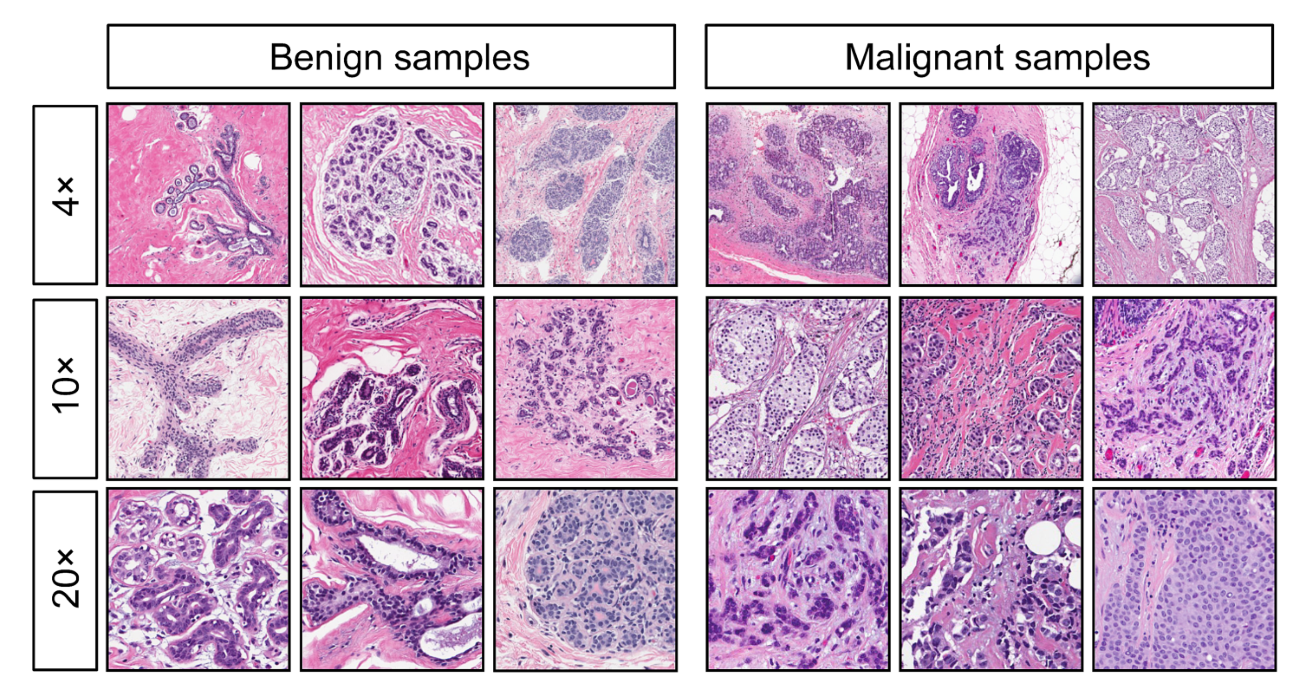

### **Estructura del dataset:**

* Número de observaciones: 569 pacientes

* Número de variables explicativas: 30 variables continuas

* Variable respuesta: binaria

  * M (0): Tumor maligno

  * B (1): Tumor benigno

Las variables explicativas corresponden a estadísticas calculadas sobre cada imagen celular, tales como media, error estándar y valor máximo (“worst”) de distintas propiedades morfológicas.

# 1. Lectura de los datos


Vamos a leer la base de datos correspondiente a Breast Cancer Wisconsin Dataset la cual se encuentra dentro del repositorio de bases de ScikitLearn y luego realizar algunos análisis descriptivos básicos para explorar la data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import (
    roc_auc_score, roc_curve,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    average_precision_score,
    accuracy_score,
    f1_score
)

import statsmodels.api as sm

In [2]:
data = load_breast_cancer() # Objeto tipo diccionario que contiene la información de la base de datos
print(data['DESCR'])

.. _breast_cancer_dataset:

Breast cancer wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

In [3]:
# Retiramos la columna de nombre Id (ya que no es una variable de nuestro interés)

dataset = pd.DataFrame(np.c_[data['data'],data['target']], columns = np.append(data['feature_names'], ['target']))
dataset["target"] = dataset["target"].map({
    0: "Maligno",
    1: "Benigno"
})

dataset.head()


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,Maligno
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,Maligno
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,Maligno
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,Maligno
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,Maligno


In [4]:
# Verificamos cuántas filas y columnas posee nuestro dataset
print(dataset.shape)

(569, 31)


In [5]:
# Mayor información acerca del conjunto de datos que estoy trabajando
print(dataset.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [6]:
# Algunas descripciones adicionales del dataset
print(type(dataset))
print(dataset.describe())

<class 'pandas.core.frame.DataFrame'>
       mean radius  mean texture  mean perimeter    mean area  \
count   569.000000    569.000000      569.000000   569.000000   
mean     14.127292     19.289649       91.969033   654.889104   
std       3.524049      4.301036       24.298981   351.914129   
min       6.981000      9.710000       43.790000   143.500000   
25%      11.700000     16.170000       75.170000   420.300000   
50%      13.370000     18.840000       86.240000   551.100000   
75%      15.780000     21.800000      104.100000   782.700000   
max      28.110000     39.280000      188.500000  2501.000000   

       mean smoothness  mean compactness  mean concavity  mean concave points  \
count       569.000000        569.000000      569.000000           569.000000   
mean          0.096360          0.104341        0.088799             0.048919   
std           0.014064          0.052813        0.079720             0.038803   
min           0.052630          0.019380        0.00

In [7]:
# Realizamos un análisis de distribución por clases

print(dataset.groupby('target').agg(['mean', 'std']).reset_index())


    target mean radius           mean texture           mean perimeter  \
                  mean       std         mean       std           mean   
0  Benigno   12.146524  1.780512    17.914762  3.995125      78.075406   
1  Maligno   17.462830  3.203971    21.604906  3.779470     115.365377   

               mean area             mean smoothness  ... worst compactness  \
         std        mean         std            mean  ...              mean   
0  11.807438  462.790196  134.287118        0.092478  ...          0.182673   
1  21.854653  978.376415  367.937978        0.102898  ...          0.374824   

            worst concavity           worst concave points            \
        std            mean       std                 mean       std   
0  0.092180        0.166238  0.140368             0.074444  0.035797   
1  0.170372        0.450606  0.181507             0.182237  0.046308   

  worst symmetry           worst fractal dimension            
            mean       std        

# 2. Gráficos descriptivos básicos


array([[<Axes: title={'center': 'mean radius'}>,
        <Axes: title={'center': 'mean texture'}>,
        <Axes: title={'center': 'mean perimeter'}>,
        <Axes: title={'center': 'mean area'}>,
        <Axes: title={'center': 'mean smoothness'}>],
       [<Axes: title={'center': 'mean compactness'}>,
        <Axes: title={'center': 'mean concavity'}>,
        <Axes: title={'center': 'mean concave points'}>,
        <Axes: title={'center': 'mean symmetry'}>,
        <Axes: title={'center': 'mean fractal dimension'}>],
       [<Axes: title={'center': 'radius error'}>,
        <Axes: title={'center': 'texture error'}>,
        <Axes: title={'center': 'perimeter error'}>,
        <Axes: title={'center': 'area error'}>,
        <Axes: title={'center': 'smoothness error'}>],
       [<Axes: title={'center': 'compactness error'}>,
        <Axes: title={'center': 'concavity error'}>,
        <Axes: title={'center': 'concave points error'}>,
        <Axes: title={'center': 'symmetry error'}>

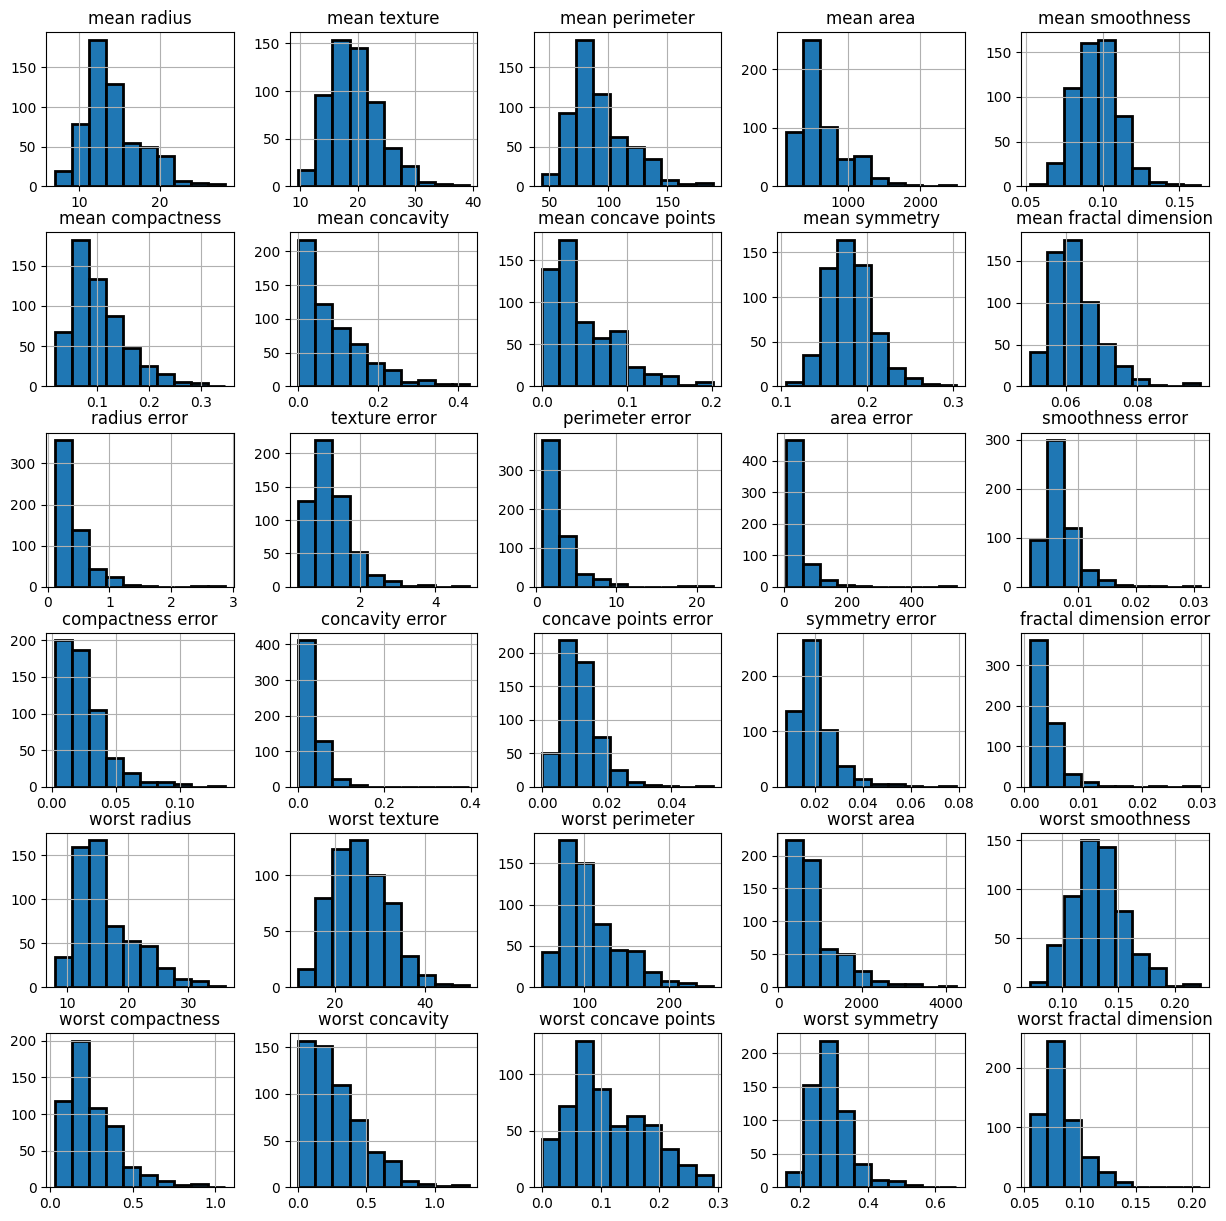

In [ ]:
# Elaboración de histogramas:

dataset.hist(edgecolor='black', linewidth=2, figsize=(15, 15))

array([[<Axes: title={'center': 'area error'}, xlabel='[target]'>,
        <Axes: title={'center': 'compactness error'}, xlabel='[target]'>,
        <Axes: title={'center': 'concave points error'}, xlabel='[target]'>,
        <Axes: title={'center': 'concavity error'}, xlabel='[target]'>,
        <Axes: title={'center': 'fractal dimension error'}, xlabel='[target]'>],
       [<Axes: title={'center': 'mean area'}, xlabel='[target]'>,
        <Axes: title={'center': 'mean compactness'}, xlabel='[target]'>,
        <Axes: title={'center': 'mean concave points'}, xlabel='[target]'>,
        <Axes: title={'center': 'mean concavity'}, xlabel='[target]'>,
        <Axes: title={'center': 'mean fractal dimension'}, xlabel='[target]'>],
       [<Axes: title={'center': 'mean perimeter'}, xlabel='[target]'>,
        <Axes: title={'center': 'mean radius'}, xlabel='[target]'>,
        <Axes: title={'center': 'mean smoothness'}, xlabel='[target]'>,
        <Axes: title={'center': 'mean symmetry'}, xl

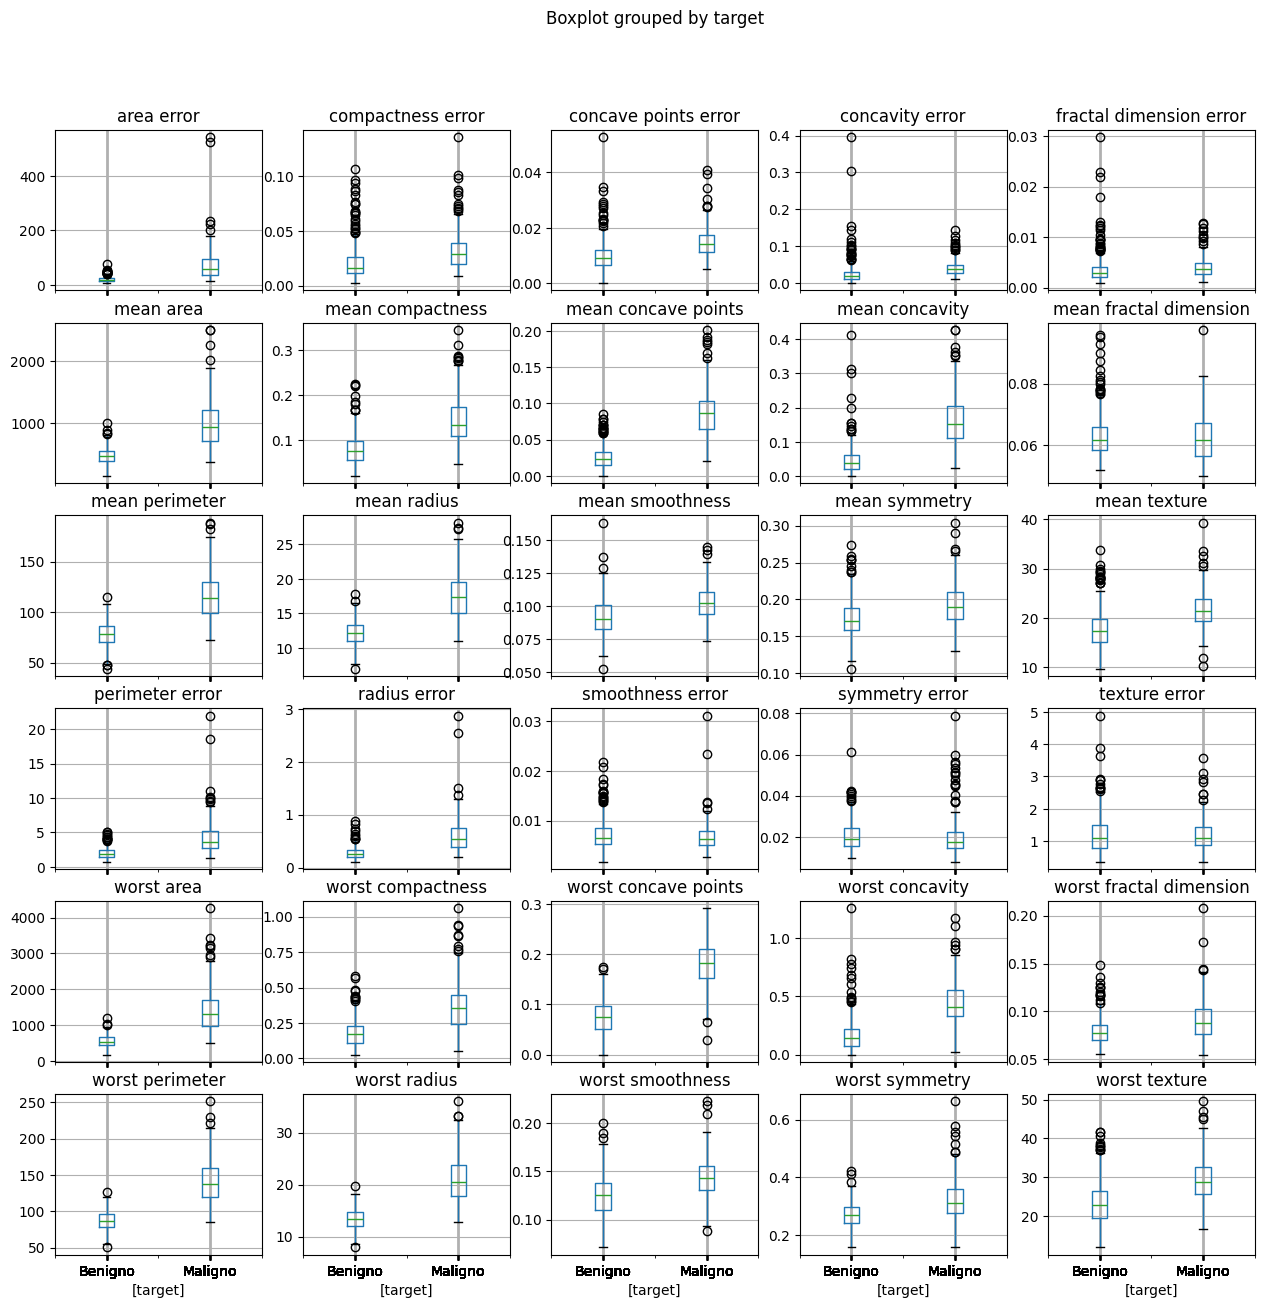

In [8]:
# Elaboración de boxplot por cada una de las especies

dataset.boxplot(by="target",figsize=(15,15), sharey=False)

Variables 1 a 10


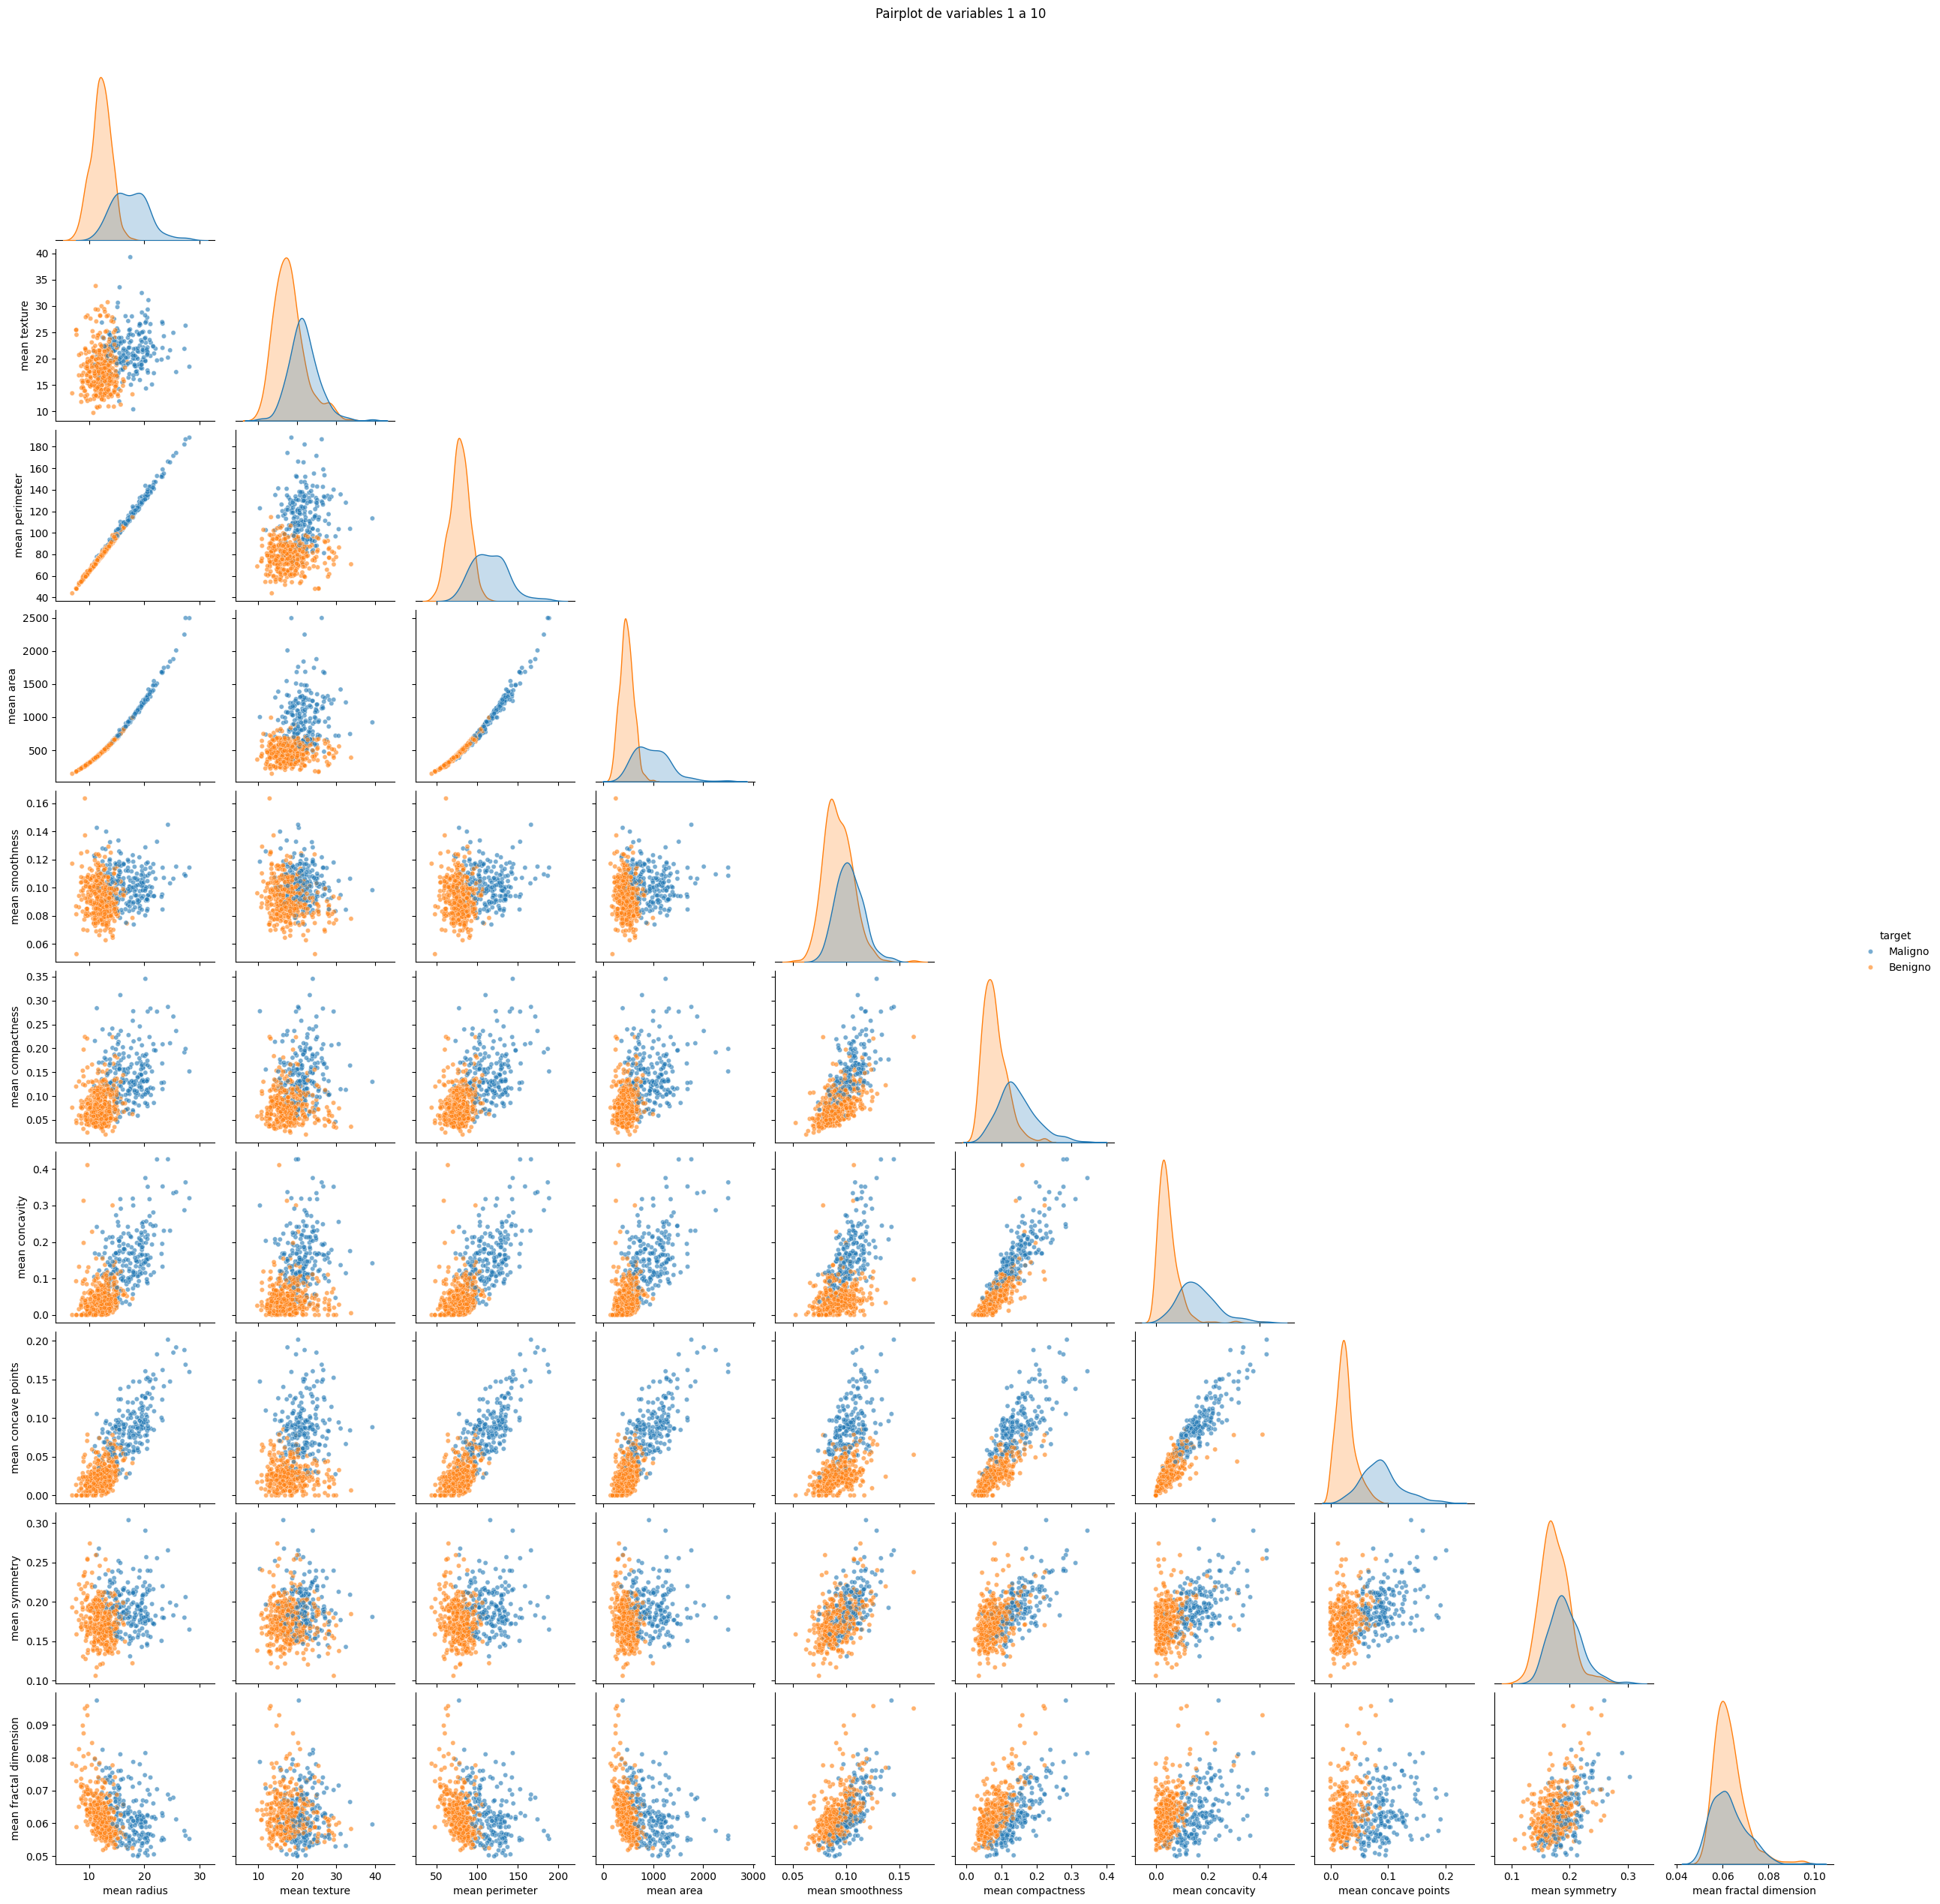

Variables 11 a 20


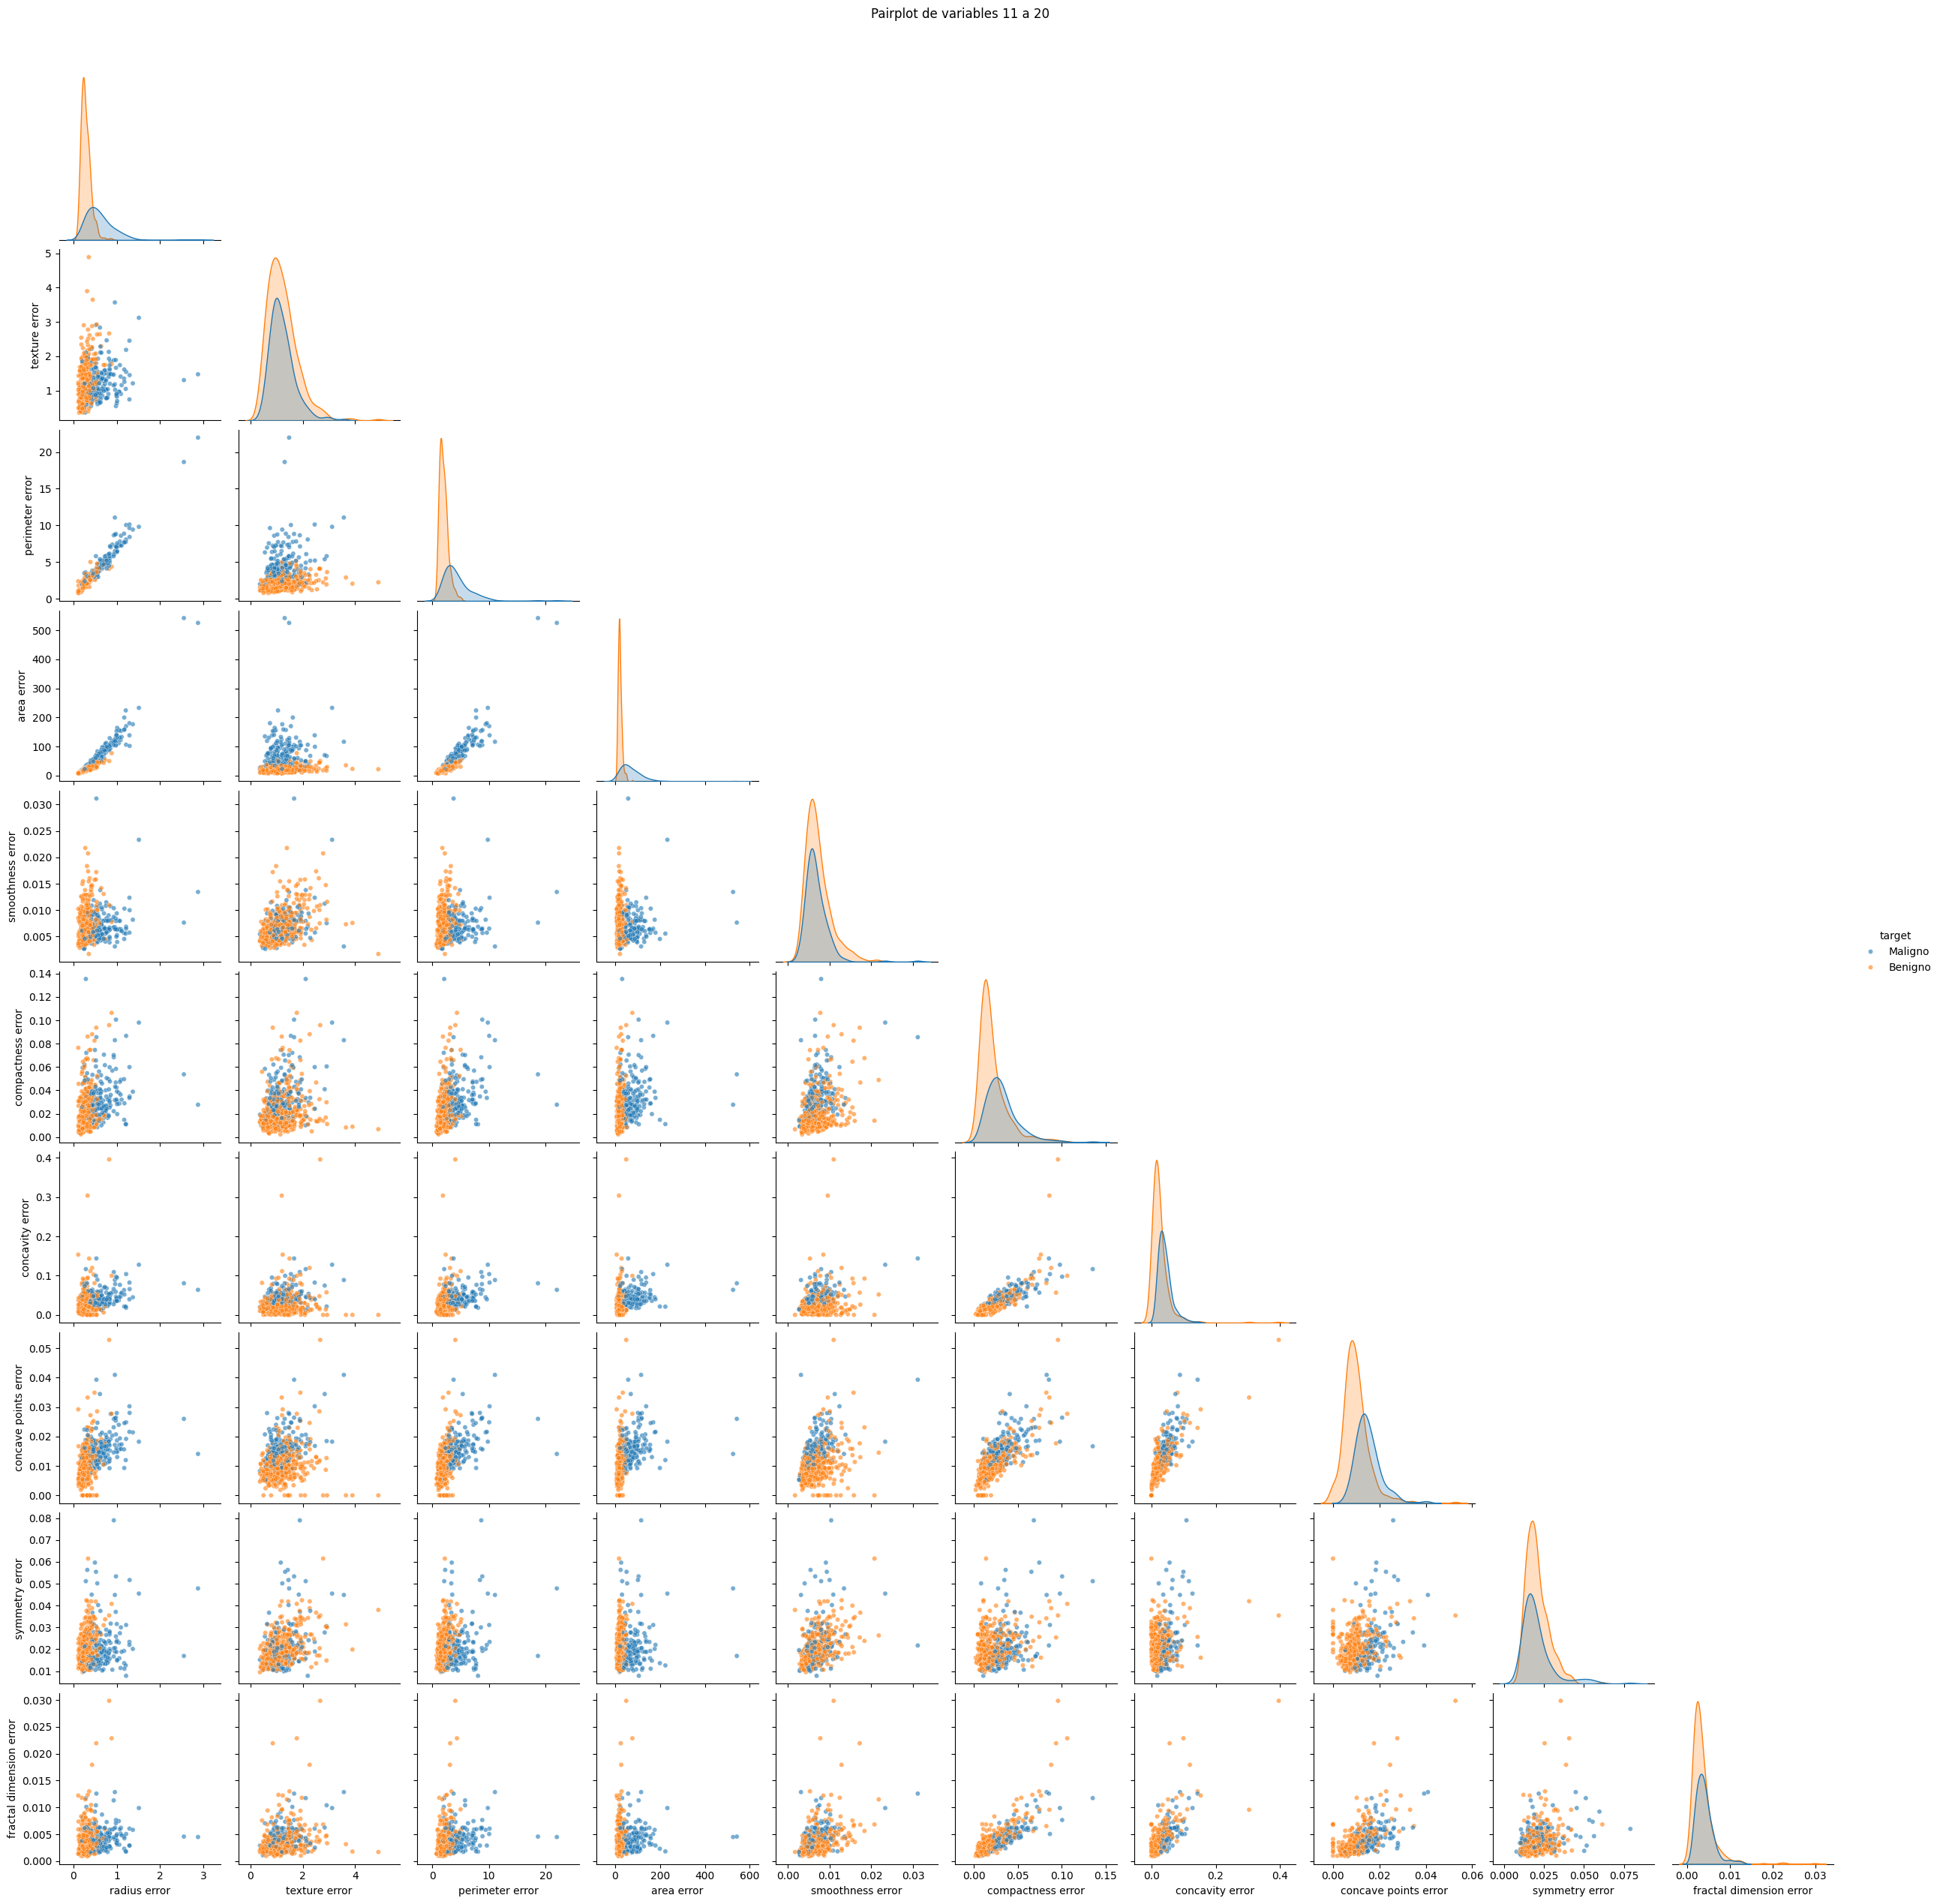

Variables 21 a 30


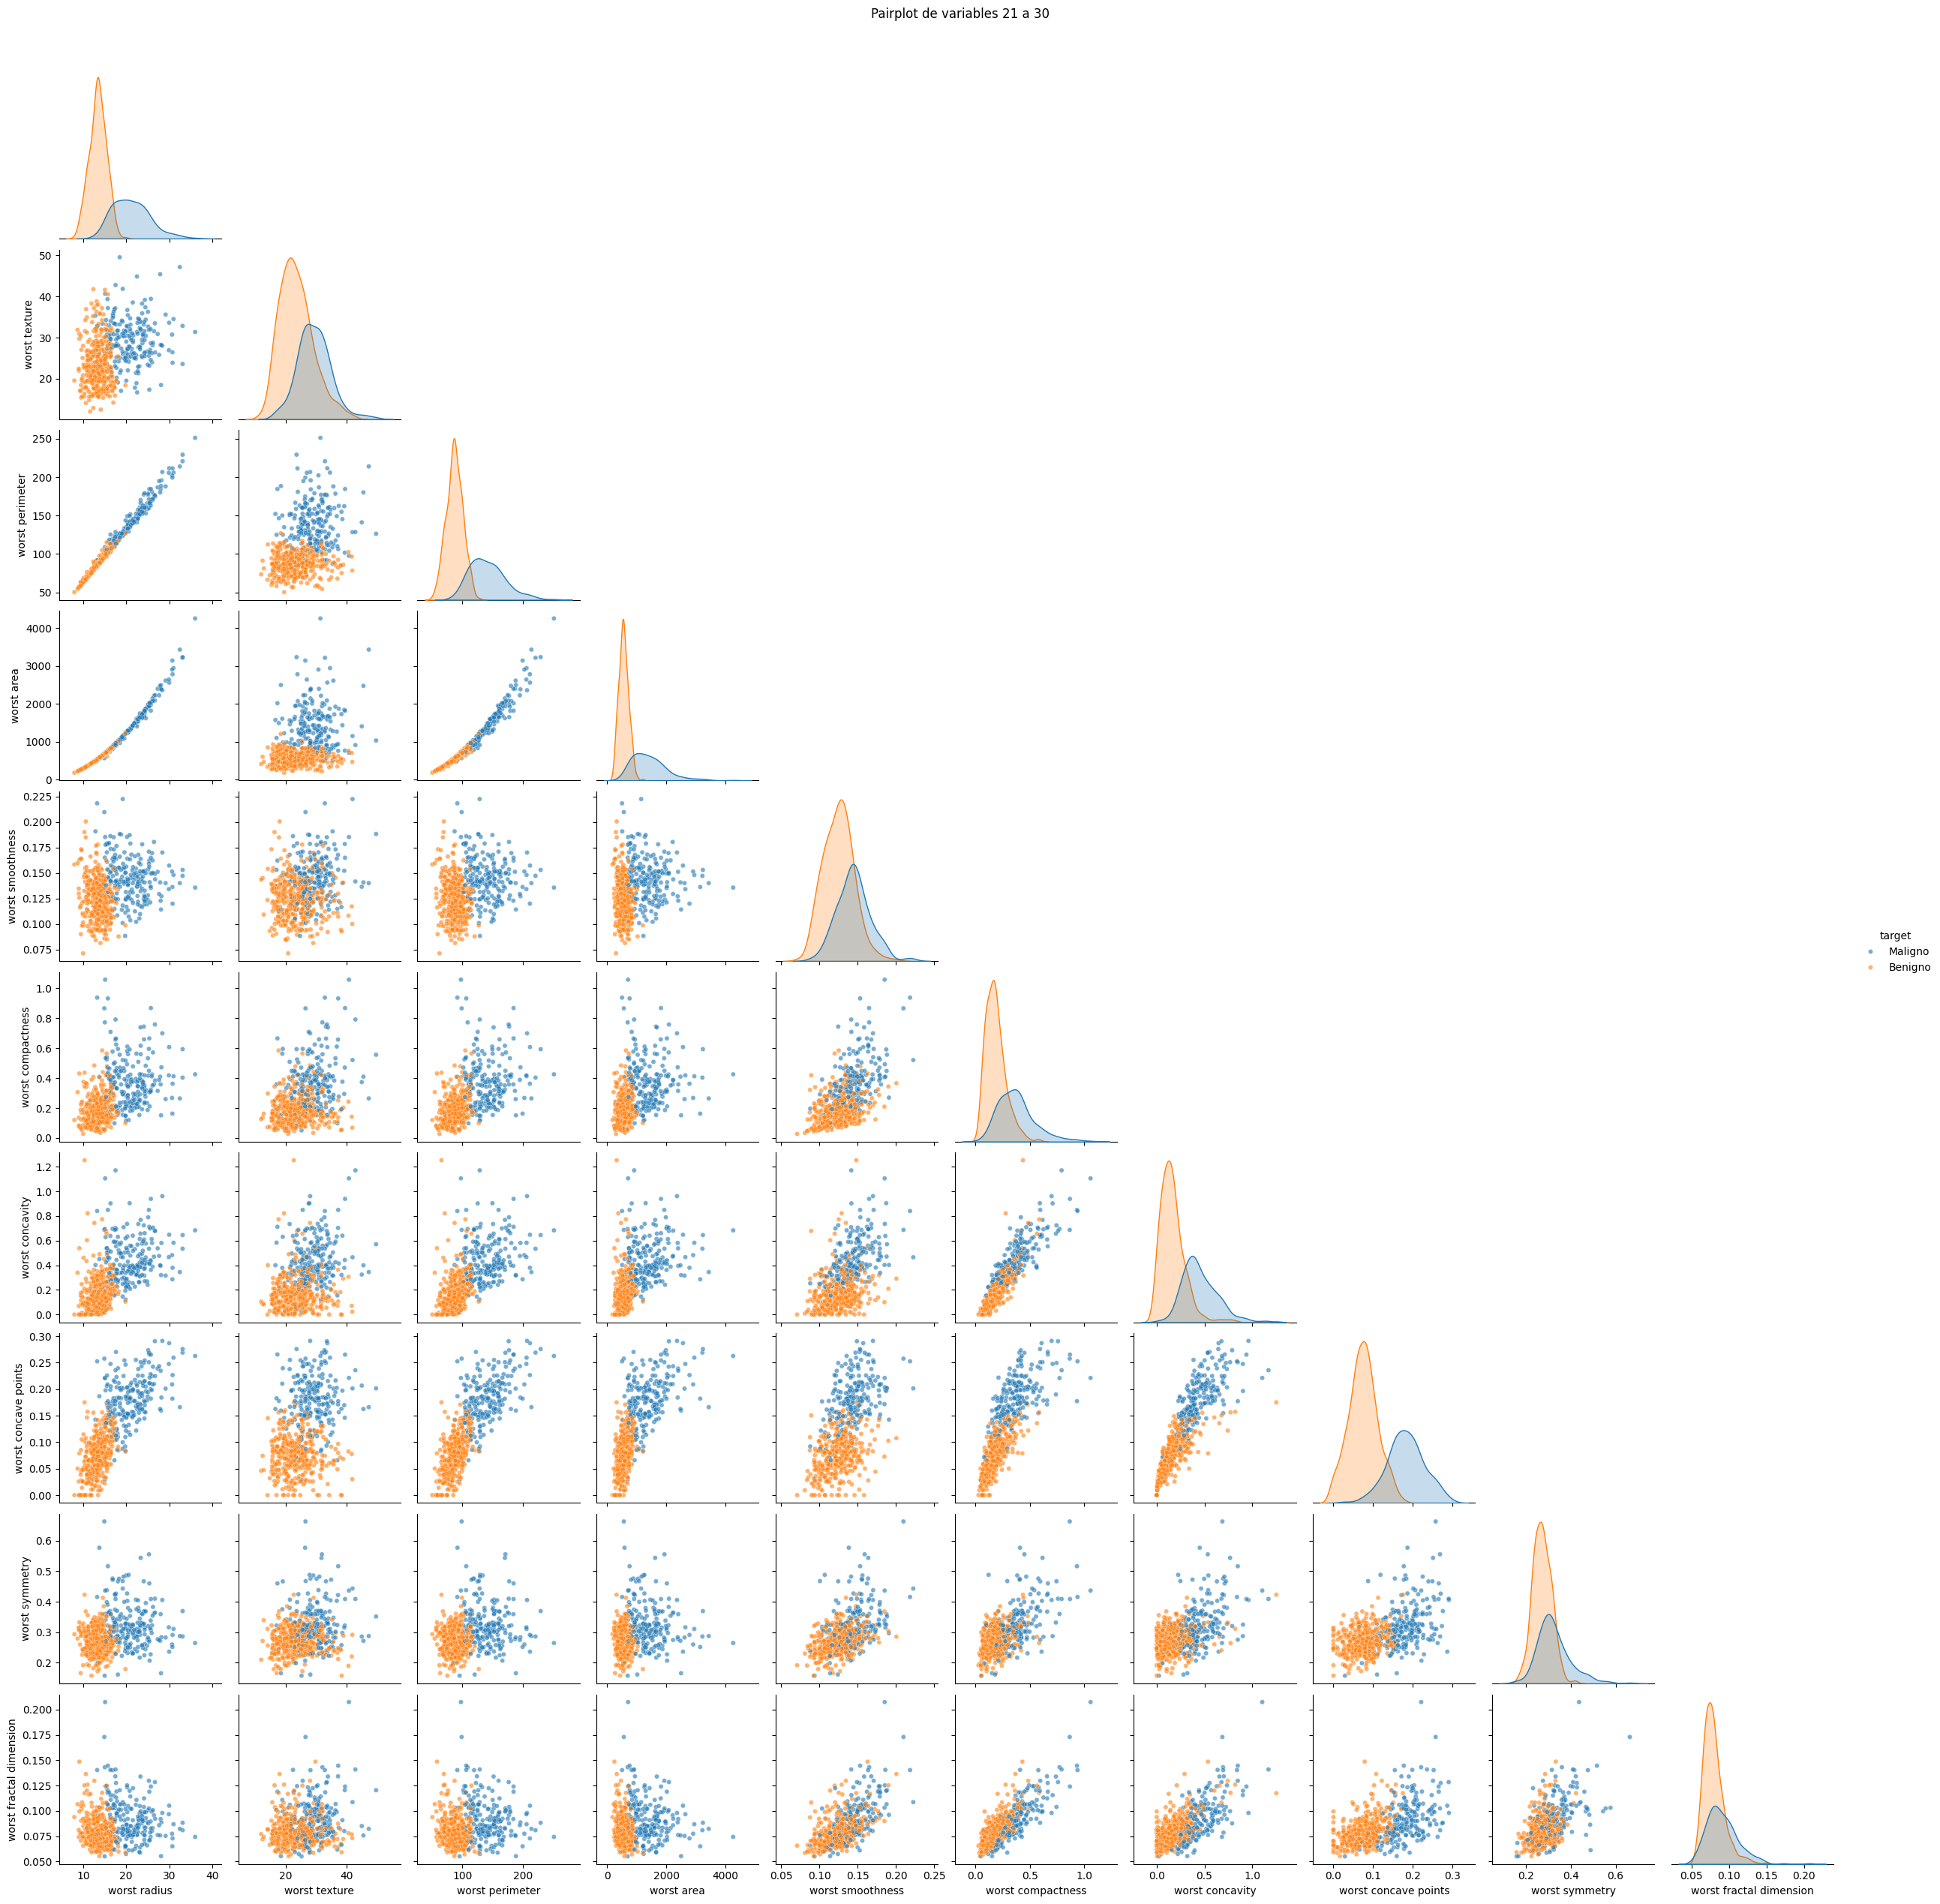

In [9]:
# Vamos a usar ahora la función pairplot de la librería seaborn para ver la relación bivariada entre cada par de características

# Número de variables por gráfico
block_size = 10

# Variables explicativas (excluyendo target)
features = [col for col in dataset.columns if col != "target"]

# Generar los bloques
for i in range(0, len(features), block_size):
    vars_block = features[i:i + block_size]

    print(f"Variables {i + 1} a {i + len(vars_block)}")

    sns.pairplot(
        dataset,
        vars=vars_block,
        hue="target",
        diag_kind="kde",
        corner=True,
        plot_kws={"alpha": 0.6, "s": 20}
    )

    plt.suptitle(
        f"Pairplot de variables {i + 1} a {i + len(vars_block)}",
        y=1.02
    )

    plt.show()


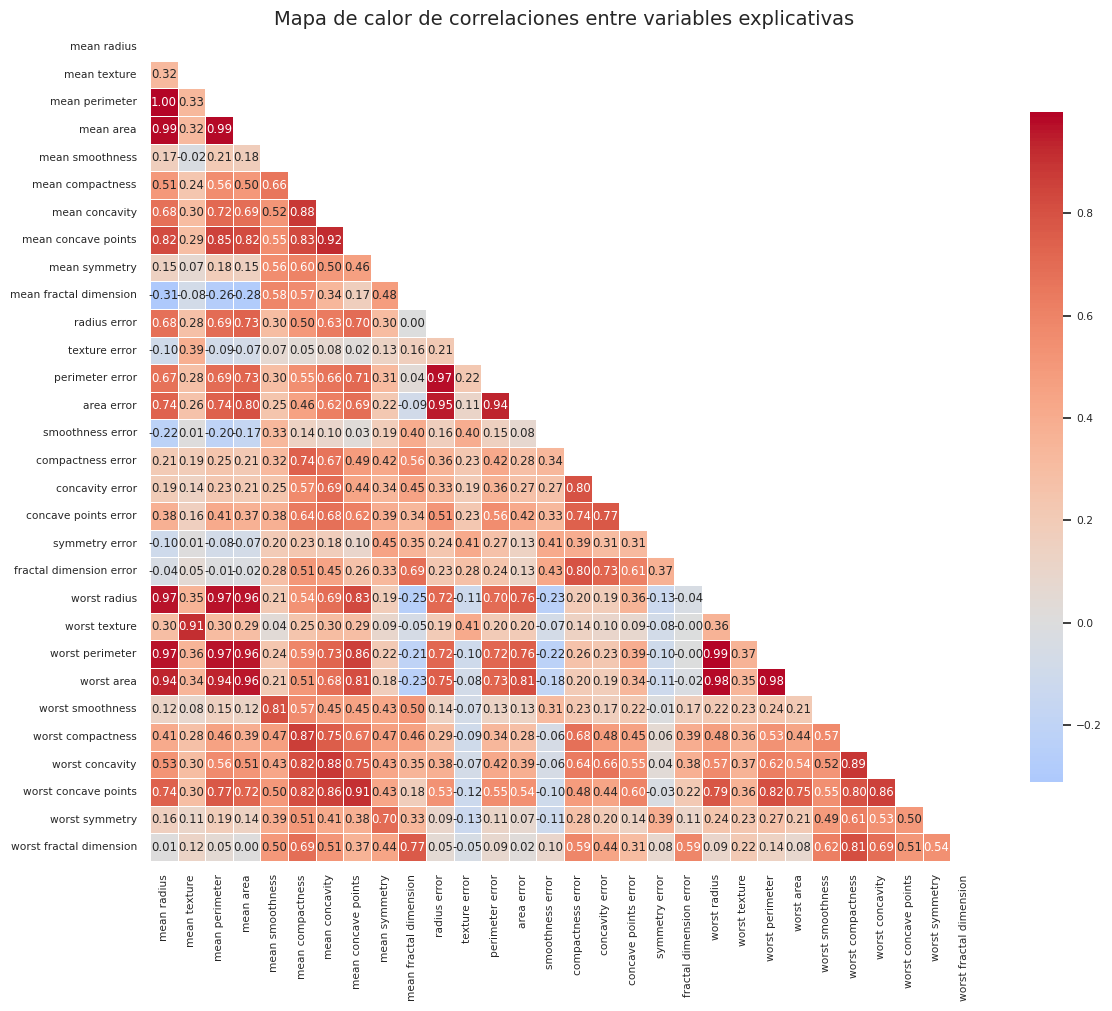

In [ ]:
# Vamos a realizar un mapa de calor de las variables explicativas del modelo:

X = dataset.iloc[:, :-1]
corr_matrix = X.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool)) # Crea una máscara para ocultar el triángulo superior

sns.set_theme(style="white", font_scale=0.7)

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)

plt.title("Mapa de calor de correlaciones entre variables explicativas", fontsize=14)
plt.tight_layout()
plt.show()

**Observación:** Se evidencia que existen variables con un alto nivel de correlación (cercano a 1). Esto es de esperarse ya que variables como el área y perímetro están altamente relacionados con el radio de las células. Vamos a establecer una regla de preselección de variables donde en pares de variables que presenten una correlación absoluta mayor a $90\%$, se seleccionará la variable que genera una mejor discriminación (GINI) del cáncer de mama.

In [10]:
# Definimos la marca del target 1: Maligno y 0: Benigno

df = dataset.copy()
df["target_bin"] = (df["target"] == "Maligno").astype(int) # Se define la marca 1 como maligno

X = df.drop(columns=["target", "target_bin"])
y = df["target_bin"]

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=123) # Particionamos la muestra y aplicamos el análisis de correlación sobre la muestra de train-validation (80%)

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,target_bin
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,Maligno,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,Maligno,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,Maligno,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,Maligno,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,Maligno,1


In [11]:
# Definimos la función para estimar el indicador de GINI
def gini_score(x, y):
    auc = roc_auc_score(y, x)
    return 2 * auc - 1

In [12]:
# Calculamos el  GINI para cada variable

gini_dict = {}
for col in X.columns:
    try:
        gini_dict[col] = gini_score(X[col], y)
    except ValueError:
        gini_dict[col] = np.nan  # por seguridad

gini_series = pd.Series(gini_dict)

In [13]:
# Estimamos el nivel de correlación absoluto entre pares de variables y en aquellas donde sea mayor a 0.9, se procede a eliminar la de menor GINI:

corr_matrix = X.corr().abs()
threshold = 0.80
vars_to_drop = set()
columns = corr_matrix.columns

for i in range(len(columns)):
    for j in range(i + 1, len(columns)):
        var1 = columns[i]
        var2 = columns[j]

        if corr_matrix.loc[var1, var2] > threshold:
            gini1 = gini_series[var1]
            gini2 = gini_series[var2]

            if gini1 >= gini2:
                vars_to_drop.add(var2)
            else:
                vars_to_drop.add(var1)

In [14]:
selected_variables = [v for v in X.columns if v not in vars_to_drop]

X_selected = X[selected_variables]

print(f"Número inicial de variables: {X.shape[1]}")
print(f"Número final de variables: {X_selected.shape[1]}")
print("\nVariables eliminadas por alta correlación:")
print(sorted(vars_to_drop))

Número inicial de variables: 30
Número final de variables: 11

Variables eliminadas por alta correlación:
['area error', 'compactness error', 'fractal dimension error', 'mean area', 'mean compactness', 'mean concave points', 'mean concavity', 'mean perimeter', 'mean radius', 'mean smoothness', 'mean texture', 'perimeter error', 'radius error', 'worst area', 'worst compactness', 'worst concave points', 'worst concavity', 'worst fractal dimension', 'worst radius']


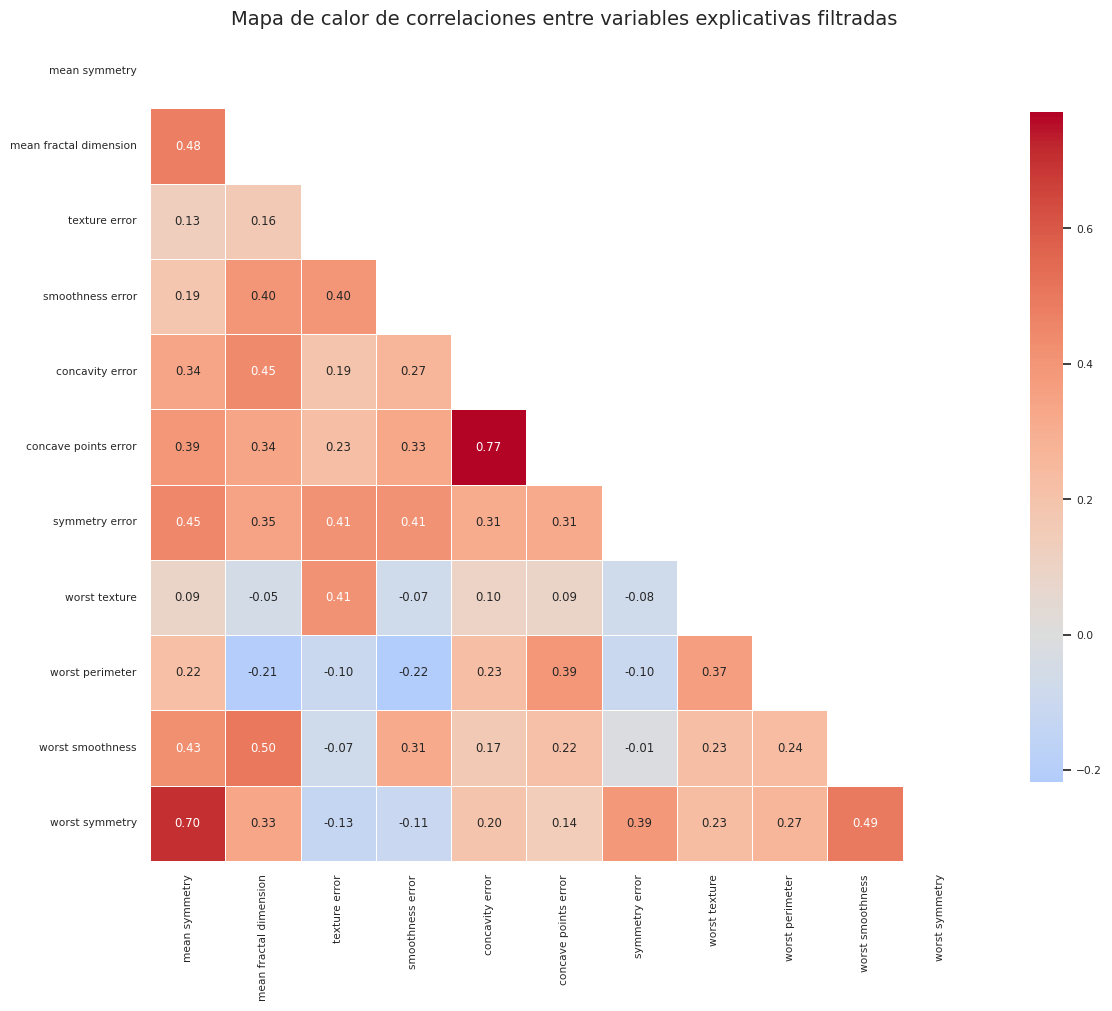

In [15]:
corr_matrix = X_selected.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool)) # Crea una máscara para ocultar el triángulo superior

sns.set_theme(style="white", font_scale=0.7)

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)

plt.title("Mapa de calor de correlaciones entre variables explicativas filtradas", fontsize=14)
plt.tight_layout()
plt.show()

# 3. Aplicación de modelo de regresión logística:

A continuación, vamos a estimar un modelo de regresión logística en 3 versiones:

* $\mathcal{M}_{1}$: Regresión logística usando todas las variables
* $\mathcal{M}_{2}$: Regresión logística usando el método de selección de variables de pasos sucesivos mixtos.
* $\mathcal{M}_{3}$: Regresión logística usando función de penalización Lasso
* $\mathcal{M}_{4}$: Regresión logística usando función de penalización Ridge
* $\mathcal{M}_{5}$: Regresión logística usando función de penalización Elastic Net

Vamos a contrastar los niveles de discriminación (GINI), accuracy, sensibilidad, especificidad y F1-Score de estos 5 modelos. Para ello vamos a particionar la muestra en 3 subgrupos: Entrenamiento ($70\%$), Validación ($15\%$) y Test ($15\%$).

In [16]:
# Construimos una función que nos permita obtener los principales indicadores de performance del modelo en test:

def compute_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    metrics = {
        "GINI": 2 * roc_auc_score(y_true, y_prob) - 1,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Sensibilidad": tp / (tp + fn),
        "Especificidad": tn / (tn + fp),
        "F1": f1_score(y_true, y_pred)
    }
    return metrics

# 3.1. Modelo $\mathcal{M}_1$: Regresión logística

In [17]:
# Definimos las bases que usaremos para el entrenamiento del modelo. Consideraremos que aquí se usará toda la muestra de train-validation para la estimación:

X_train_logit = X_temp[selected_variables].copy()
y_train_logit = y_temp.copy()

X_test_logit = X_test[selected_variables].copy()
y_test_logit = y_test.copy()

In [18]:
scaler = StandardScaler()

X_train_final = scaler.fit_transform(X_train_logit)
X_test_final  = scaler.transform(X_test_logit)

In [19]:
# Estimación del modelo de regresión logística:

logit_m1 = sm.Logit(y_train_logit, sm.add_constant(X_train_logit)).fit()
logit_m1.summary()

Optimization terminated successfully.
         Current function value: 0.060940
         Iterations 12


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:             target_bin   No. Observations:                  455
Model:                          Logit   Df Residuals:                      443
Method:                           MLE   Df Model:                           11
Date:                Sat, 25 Jul 2026   Pseudo R-squ.:                  0.9078
Time:                        16:24:15   Log-Likelihood:                -27.728
converged:                       True   LL-Null:                       -300.69
Covariance Type:            nonrobust   LLR p-value:                5.067e-110
==========================================================================================
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                    -50.6498     10.062     -5.034      0.000     -70.371     -30.928
mean symmetry             14.1269     30.668      0.461      0.645     -45.981      74.235
mean fractal dimension  -167.5042    113.890     -1.471      0.141    -390.724      55.716
texture error             -0.4479      1.818     -0.246      0.805      -4.012       3.116
smoothness error         -99.7437    243.215     -0.410      0.682    -576.436     376.949
concavity error            3.5019     31.121      0.113      0.910     -57.494      64.498
concave points error     176.7290    150.990      1.170      0.242    -119.207     472.665
symmetry error           -16.4027     81.288     -0.202      0.840    -175.724     142.919
worst texture              0.3869      0.129      3.000      0.003       0.134       0.640
worst perimeter            0.2562      0.053      4.814      0.000       0.152       0.361
worst smoothness         112.7702     38.479      2.931      0.003      37.352     188.188
worst symmetry            16.2809     15.201      1.071      0.284     -13.512      46.074
==========================================================================================

Possibly complete quasi-separation: A fraction 0.47 of observations can be
perfectly predicted. This might indicate that there is complete
quasi-separation. In this case some parameters will not be identified.
"""

Analizamos la interpretación de los coeficientes mediante el odds-ratio:

In [20]:
params = logit_m1.params
conf = logit_m1.conf_int()

or_table = pd.DataFrame({
    "Beta": params,
    "Odds_Ratio": np.exp(params),
    "p_value": logit_m1.pvalues
}).sort_values("Odds_Ratio", ascending=False)

or_table

,Beta,Odds_Ratio,p_value
concave points error,176.728961,5.654740e+76,2.418136e-01
worst smoothness,112.770244,9.451372e+48,3.382233e-03
worst symmetry,16.280863,1.176763e+07,2.841435e-01
mean symmetry,14.126877,1.365290e+06,6.450570e-01
concavity error,3.501870,3.317743e+01,9.104079e-01
worst texture,0.386858,1.472347e+00,2.697349e-03
worst perimeter,0.256231,1.292052e+00,1.482003e-06
texture error,-0.447910,6.389619e-01,8.054327e-01
symmetry error,-16.402728,7.522907e-08,8.400847e-01
const,-50.649787,1.007110e-22,4.812362e-07


In [21]:
y_prob_test_m1 = logit_m1.predict(sm.add_constant(X_test_final))
metrics_m1 = compute_metrics(y_test_logit, y_prob_test_m1)

print(f"GINI: {metrics_m1['GINI']:.3f}")
print(f"Accuracy: {metrics_m1['Accuracy']:.3f}")
print(f"Sensibilidad: {metrics_m1['Sensibilidad']:.3f}")

GINI: 0.793
Accuracy: 0.825
Sensibilidad: 0.857


# 3.2. Modelo $\mathcal{M}_2$: Regresión Logística usando selección de variables

In [22]:
def cv_auc(X, y, vars_list, cv=5):
    """
    Calcula AUC promedio por validación cruzada estratificada
    """
    skf = StratifiedKFold(n_splits=cv, shuffle=True, random_state=42)
    aucs = []

    for tr, val in skf.split(X[vars_list], y):
        model = LogisticRegression(max_iter=1000)
        model.fit(X[vars_list].iloc[tr], y.iloc[tr])
        prob = model.predict_proba(X[vars_list].iloc[val])[:, 1]
        aucs.append(roc_auc_score(y.iloc[val], prob))

    return np.mean(aucs)

In [23]:
def stepwise_forward_backward(X, y, cv=5, tol=1e-4):
    """
    Stepwise bidireccional (forward-backward) optimizando AUC CV
    """
    remaining = list(X.columns)
    selected = []
    current_auc = 0.5  # baseline aleatorio
    history = []

    improved = True

    while improved:
        improved = False

        # =====================
        # FORWARD STEP
        # =====================
        forward_scores = []

        for var in remaining:
            auc = cv_auc(X, y, selected + [var], cv)
            forward_scores.append((auc, var))

        if forward_scores:
            best_auc, best_var = max(forward_scores)

            if best_auc > current_auc + tol:
                selected.append(best_var)
                remaining.remove(best_var)
                current_auc = best_auc
                history.append(("add", best_var, current_auc))
                improved = True

        # =====================
        # BACKWARD STEP
        # =====================
        while len(selected) > 1:
            backward_scores = []

            for var in selected:
                vars_try = [v for v in selected if v != var]
                auc = cv_auc(X, y, vars_try, cv)
                backward_scores.append((auc, var))

            best_auc, worst_var = max(backward_scores)

            if best_auc > current_auc + tol:
                selected.remove(worst_var)
                remaining.append(worst_var)
                current_auc = best_auc
                history.append(("remove", worst_var, current_auc))
                improved = True
            else:
                break

    return selected, history


In [24]:
selected_vars_m2, cv_history_m2 = stepwise_forward_backward(pd.DataFrame(X_train_final, columns=selected_variables), y_train_logit)
print(selected_vars_m2)
print(cv_history_m2)

['worst perimeter', 'worst texture', 'worst smoothness', 'worst symmetry']
[('add', 'worst perimeter', np.float64(0.9769865841073271)), ('add', 'worst texture', np.float64(0.9886480908152734)), ('add', 'worst smoothness', np.float64(0.993498452012384)), ('add', 'worst symmetry', np.float64(0.9943240454076367))]


In [25]:
from sklearn.linear_model import LogisticRegression

X_train_final_df = pd.DataFrame(X_train_final, columns=selected_variables)
X_test_final_df = pd.DataFrame(X_test_final, columns=selected_variables)

logit_m2 = LogisticRegression()
logit_m2.fit(X_train_final_df[selected_vars_m2], y_train_logit)

y_pred_m2 = logit_m2.predict(X_test_final_df[selected_vars_m2]) # Predicción en muestra de test

# Resumen de los resultados de clasificación:

metrics_m2 = compute_metrics(y_test_logit, y_pred_m2)

print(f"GINI: {metrics_m2['GINI']:.3f}")
print(f"Accuracy: {metrics_m2['Accuracy']:.3f}")
print(f"Sensibilidad: {metrics_m2['Sensibilidad']:.3f}")

GINI: 0.887
Accuracy: 0.947
Sensibilidad: 0.929


# 3.3. Modelo $\mathcal{M}_{3}$: Regresión Logística con penalización $L_1$ (Lasso):

In [26]:
lasso = LogisticRegressionCV(
    penalty="l1",
    solver="saga",
    cv=5,
    scoring="roc_auc",
    max_iter=5000
)

lasso.fit(X_train_final, y_train_logit)

LogisticRegressionCV(cv=5, max_iter=5000, penalty='l1', scoring='roc_auc',
                     solver='saga')

In [27]:
# Hallamos el Lambda óptimo para Lasso del problema:

lambda_opt = 1/lasso.C_[0]
lambda_opt

np.float64(2.782559402207126)

In [28]:
betas = pd.Series(
    lasso.coef_[0],
    index=X_train_final_df.columns,
    name="Beta"
)

betas_no_cero = betas[betas != 0]
betas_no_cero # Variables seleccionadas por Lasso

,Beta
mean symmetry,0.001267
concave points error,0.365127
worst texture,1.230401
worst perimeter,5.281316
worst smoothness,1.086128
worst symmetry,0.573557


In [29]:
odds_ratios = np.exp(betas_no_cero)

or_table = pd.DataFrame({
    "Beta": betas_no_cero,
    "Odds_Ratio": odds_ratios
}).sort_values("Odds_Ratio", ascending=False)

or_table

,Beta,Odds_Ratio
worst perimeter,5.281316,196.628544
worst texture,1.230401,3.422602
worst smoothness,1.086128,2.962780
worst symmetry,0.573557,1.774568
concave points error,0.365127,1.440697
mean symmetry,0.001267,1.001268


In [30]:
# Resumen de los resultados del modelo M3:

y_prob_test_m3 = lasso.predict_proba(X_test_final)[:, 1]
metrics_m3 = compute_metrics(y_test_logit, y_prob_test_m3)

print(f"GINI: {metrics_m3['GINI']:.3f}")
print(f"Accuracy: {metrics_m3['Accuracy']:.3f}")
print(f"Sensibilidad: {metrics_m3['Sensibilidad']:.3f}")

GINI: 0.962
Accuracy: 0.965
Sensibilidad: 0.952


# 3.4. Modelo $\mathcal{M}_4$: Regresión logística con penalización $L_{2}$ (Ridge)

In [76]:
scaler = StandardScaler()

X_train_final = scaler.fit_transform(X_train_logit)
X_test_final  = scaler.transform(X_test_logit)

ridge = LogisticRegressionCV(
    penalty="l2",
    cv=5,
    scoring="roc_auc",
    max_iter=5000
)

ridge.fit(X_train_final, y_train_logit)

LogisticRegressionCV(cv=5, max_iter=5000, scoring='roc_auc')

In [77]:
# Hallamos el Lambda óptimo estimado:

lambda_opt = 1 / ridge.C_[0]
lambda_opt

np.float64(2.782559402207126)

In [78]:
# Resumimos los betas y odds-ratios estimados:

betas = pd.Series(
    ridge.coef_[0],
    index=X_train_final_df.columns,
    name="Beta"
)

odds_ratios = np.exp(betas)

or_table = pd.DataFrame({
    "Beta": betas,
    "Odds_Ratio": odds_ratios
}).sort_values("Odds_Ratio", ascending=False)

or_table

,Beta,Odds_Ratio
worst perimeter,3.057434,21.272897
worst texture,1.227198,3.411655
worst smoothness,1.121236,3.068646
concave points error,0.799612,2.224678
worst symmetry,0.590952,1.805707
mean symmetry,0.241111,1.272662
concavity error,0.140836,1.151236
smoothness error,-0.145648,0.864462
symmetry error,-0.147981,0.862448
texture error,-0.300122,0.740728


In [79]:
# Resumen de los resultados del modelo M4:

y_prob_test_m4 = ridge.predict_proba(X_test_final)[:, 1]
metrics_m4 = compute_metrics(y_test_logit, y_prob_test_m4)

print(f"GINI: {metrics_m4['GINI']:.3f}")
print(f"Accuracy: {metrics_m4['Accuracy']:.3f}")
print(f"Sensibilidad: {metrics_m4['Sensibilidad']:.3f}")

GINI: 0.957
Accuracy: 0.947
Sensibilidad: 0.929


# 3.5. Modelo $\mathcal{M}_{5}$: Regresión logística usando penalización Elastic-Net

In [35]:
elastic = LogisticRegressionCV(
    penalty="elasticnet",
    solver="saga",
    l1_ratios = [0.1,0.2,0.5,0.8,0.9],
    cv=5,
    scoring="roc_auc",
    max_iter=5000
)

elastic.fit(X_train_final, y_train_logit)

LogisticRegressionCV(cv=5, l1_ratios=[0.1, 0.2, 0.5, 0.8, 0.9], max_iter=5000,
                     penalty='elasticnet', scoring='roc_auc', solver='saga')

In [36]:
# Hallamos la combinación óptima de lambda (penalización) y alpha (ponderación) óptimos:
lambda_opt = 1 / elastic.C_[0]
l1_ratio_opt = elastic.l1_ratio_[0]
print(lambda_opt) # Penalización óptima
print(l1_ratio_opt) # Ponderación EN óptima

21.544346900318843
0.9


In [37]:
betas = pd.Series(
    elastic.coef_[0],
    index=X_train_final_df.columns,
    name="Beta"
)

betas_no_cero = betas[betas != 0]
betas_no_cero

odds_ratios = np.exp(betas_no_cero)

or_table = pd.DataFrame({
    "Beta": betas_no_cero,
    "Odds_Ratio": odds_ratios
}).sort_values("Odds_Ratio", ascending=False)

or_table

,Beta,Odds_Ratio
worst perimeter,2.154139,8.620466
worst texture,0.422908,1.526393
worst smoothness,0.412353,1.510368
worst symmetry,0.213947,1.238557
concave points error,0.114646,1.121476


In [38]:
# Resumen de los resultados del modelo M5:

y_prob_test_m5 = elastic.predict_proba(X_test_final)[:, 1]
metrics_m5 = compute_metrics(y_test_logit, y_prob_test_m5)

print(f"GINI: {metrics_m5['GINI']:.3f}")
print(f"Accuracy: {metrics_m5['Accuracy']:.3f}")
print(f"Sensibilidad: {metrics_m5['Sensibilidad']:.3f}")


GINI: 0.963
Accuracy: 0.965
Sensibilidad: 0.929


# 4. Comparación final de modelos

Ahora analizamos los 5 modelos estimados y verificamos cuál modelo resulta ser el mejor entre estos:

In [39]:
# Creamos una tabla para guardar los resultados finales

results = pd.DataFrame.from_dict({
    "M1_Logit": metrics_m1,
    "M2_Stepwise": metrics_m2,
    "M3_Lasso": metrics_m3,
    "M4_Ridge": metrics_m4,
    "M5_ElasticNet": metrics_m5
}, orient="index")

results

,GINI,Accuracy,Sensibilidad,Especificidad,F1
M1_Logit,0.792659,0.824561,0.857143,0.805556,0.782609
M2_Stepwise,0.886905,0.947368,0.928571,0.958333,0.928571
M3_Lasso,0.962302,0.964912,0.952381,0.972222,0.952381
M4_Ridge,0.957011,0.947368,0.928571,0.958333,0.928571
M5_ElasticNet,0.962963,0.964912,0.928571,0.986111,0.951220


**Observación:** ¿Con qué modelo nos quedamos? ¿Cuál de todas las métricas sería la más recomendable usar para esta situación? ¿Por qué?

# 4. Regresión logística con Componentes Principales


In [40]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

In [43]:
# Aplicamos una validación cruzada estratificada

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

p = X_temp.shape[1] # Número total de variables originales
K = cv.get_n_splits() # Cantidad de folds

In [44]:
# ==========================================================
# Para cada posible número de componentes:
#
#   1. Estandarizamos únicamente el fold de entrenamiento.
#   2. Ajustamos el ACP.
#   3. Proyectamos train y validación.
#   4. Ajustamos la regresión logística.
#   5. Calculamos el GINI sobre el fold de validación.
# ==========================================================

gini_mean = []
gini_sd = []
gini_se = []

for n_comp in range(1, p + 1):

    # GINI obtenido en cada fold
    gini_fold = []

    for train_idx, valid_idx in cv.split(X_temp, y_temp):

        # --------------------------------------------------
        # Separar train y validación
        # --------------------------------------------------

        X_train = X_temp.iloc[train_idx]
        X_valid = X_temp.iloc[valid_idx]

        y_train = y_temp.iloc[train_idx]
        y_valid = y_temp.iloc[valid_idx]

        scaler = StandardScaler()

        X_train_std = scaler.fit_transform(X_train)
        X_valid_std = scaler.transform(X_valid)

        # --------------------------------------------------
        # Aplicamos el PCA
        # --------------------------------------------------

        pca = PCA(n_components=n_comp)

        X_train_pca = pca.fit_transform(X_train_std)
        X_valid_pca = pca.transform(X_valid_std)

        # --------------------------------------------------
        # Regresión logística
        # --------------------------------------------------

        modelo = LogisticRegression(max_iter=5000)
        modelo.fit(X_train_pca, y_train)

        # --------------------------------------------------
        # Probabilidades de la clase positiva
        # --------------------------------------------------

        prob = modelo.predict_proba(X_valid_pca)[:, 1]

        auc = roc_auc_score(y_valid, prob)

        gini = 2 * auc - 1

        gini_fold.append(gini)

    # ======================================================
    # Resumen de la validación cruzada
    # ======================================================

    gini_fold = np.array(gini_fold)

    gini_mean.append(gini_fold.mean())
    gini_sd.append(gini_fold.std(ddof=1))
    gini_se.append(gini_fold.std(ddof=1) / np.sqrt(K))


In [45]:
gini_mean = np.array(gini_mean)
gini_sd = np.array(gini_sd)
gini_se = np.array(gini_se)

# ----------------------------------------------------------
# Mejor modelo según el GINI promedio
# ----------------------------------------------------------

best_index = np.argmax(gini_mean)

best_components = best_index + 1

best_gini = gini_mean[best_index]

best_se = gini_se[best_index]

# ----------------------------------------------------------
# Umbral de la regla 1-SE
# ----------------------------------------------------------

threshold = best_gini - best_se

# ----------------------------------------------------------
# Se elige el modelo MÁS SIMPLE cuyo desempeño
# esté dentro de un error estándar del mejor.
# ----------------------------------------------------------

selected_index = np.where(gini_mean >= threshold)[0][0]

selected_components = selected_index + 1

print(f"Mejor GINI promedio : {best_gini:.4f}")
print(f"Error estándar      : {best_se:.4f}")
print(f"Umbral 1-SE         : {threshold:.4f}")
print(f"Componentes óptimas (máximo GINI): {best_components}")
print(f"Componentes seleccionadas (1-SE): {selected_components}")

Mejor GINI promedio : 0.9948
Error estándar      : 0.0028
Umbral 1-SE         : 0.9920
Componentes óptimas (máximo GINI): 13
Componentes seleccionadas (1-SE): 9


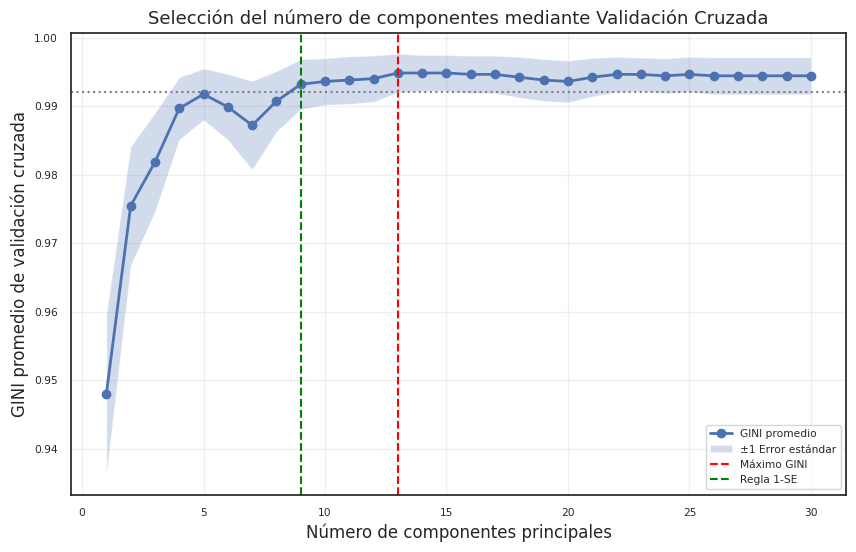

In [46]:
plt.figure(figsize=(10,6))

# ==========================================================
# GINI promedio
# ==========================================================

plt.plot(
    range(1, p + 1),
    gini_mean,
    marker="o",
    linewidth=2,
    label="GINI promedio"
)

# ==========================================================
# Intervalo ±1 Error Estándar
# ==========================================================

plt.fill_between(
    range(1, p + 1),
    gini_mean - gini_se,
    gini_mean + gini_se,
    alpha=0.25,
    label="±1 Error estándar"
)

# ==========================================================
# Mejor modelo
# ==========================================================

plt.axvline(
    best_components,
    color="red",
    linestyle="--",
    label="Máximo GINI"
)

# ==========================================================
# Modelo seleccionado por la regla 1-SE
# ==========================================================

plt.axvline(
    selected_components,
    color="green",
    linestyle="--",
    label="Regla 1-SE"
)

# ==========================================================
# Umbral de selección
# ==========================================================

plt.axhline(
    threshold,
    color="gray",
    linestyle=":"
)

plt.xlabel("Número de componentes principales", fontsize=12)
plt.ylabel("GINI promedio de validación cruzada", fontsize=12)
plt.title("Selección del número de componentes mediante Validación Cruzada", fontsize=13)

plt.grid(alpha=0.3)
plt.legend()

plt.show()

In [47]:
# ===============================================================
# Con el número óptimo de componentes, volvemos a correr el PCA
# ===============================================================

scaler = StandardScaler()

X_train_std = scaler.fit_transform(X_temp)
X_test_std = scaler.transform(X_test)

# ----------------------------------------------------------
# PCA final
# ----------------------------------------------------------

pca = PCA(n_components=selected_components)

X_train_pca = pca.fit_transform(X_train_std)
X_test_pca = pca.transform(X_test_std)

# ----------------------------------------------------------
# Regresión logística final
# ----------------------------------------------------------

modelo = LogisticRegression(max_iter=5000)

modelo.fit(X_train_pca, y_temp)

LogisticRegression(max_iter=5000)

In [49]:
# Probabilidades

prob_train = modelo.predict_proba(X_train_pca)[:,1]
prob_test = modelo.predict_proba(X_test_pca)[:,1]

# Métricas en muestra de test

metricas_train = compute_metrics(y_temp, prob_train)
metricas_test = compute_metrics(y_test, prob_test)

results.loc["M6_Logit_PCA"] = metricas_test
results

,GINI,Accuracy,Sensibilidad,Especificidad,F1
M1_Logit,0.792659,0.824561,0.857143,0.805556,0.782609
M2_Stepwise,0.886905,0.947368,0.928571,0.958333,0.928571
M3_Lasso,0.962302,0.964912,0.952381,0.972222,0.952381
M4_Ridge,0.957011,0.947368,0.928571,0.958333,0.928571
M5_ElasticNet,0.962963,0.964912,0.928571,0.986111,0.951220
M6_Logit_PCA,0.971561,0.964912,0.976190,0.958333,0.953488


In [51]:
# Varianza explicada por cada componente
var_exp = pca.explained_variance_ratio_

# Varianza acumulada
var_exp_acum = np.cumsum(var_exp)

tabla_var = pd.DataFrame({
    "Componente": np.arange(1, selected_components + 1),
    "Varianza explicada": var_exp,
    "Varianza acumulada": var_exp_acum
})

tabla_var

,Componente,Varianza explicada,Varianza acumulada
0,1,0.446815,0.446815
1,2,0.185589,0.632404
2,3,0.097282,0.729686
3,4,0.065363,0.795049
4,5,0.053007,0.848056
5,6,0.041007,0.889063
6,7,0.021912,0.910975
7,8,0.015462,0.926437
8,9,0.013918,0.940355


In [52]:
# ==========================================================
# Número de componentes a utilizar
# ==========================================================

n_components = 5

# ==========================================================
# Estandarización
# (se reutiliza el mismo procedimiento que antes)
# ==========================================================

scaler = StandardScaler()

X_train_std = scaler.fit_transform(X_temp)
X_test_std = scaler.transform(X_test)

# ==========================================================
# PCA con las primeras 5 componentes
# ==========================================================

pca = PCA(n_components=n_components)

X_train_pca = pca.fit_transform(X_train_std)
X_test_pca = pca.transform(X_test_std)

# ==========================================================
# Ajuste de la regresión logística
# ==========================================================

modelo_pca5 = LogisticRegression(max_iter=5000)

modelo_pca5.fit(X_train_pca, y_temp)

# ==========================================================
# Predicciones
# ==========================================================

prob_train = modelo_pca5.predict_proba(X_train_pca)[:, 1]
prob_test = modelo_pca5.predict_proba(X_test_pca)[:, 1]

# ==========================================================
# Métricas
# ==========================================================

metricas_test_pca5 = compute_metrics(y_test, prob_test)

results.loc["M7_Logit_PCA5"] = metricas_test_pca5

results

,GINI,Accuracy,Sensibilidad,Especificidad,F1
M1_Logit,0.792659,0.824561,0.857143,0.805556,0.782609
M2_Stepwise,0.886905,0.947368,0.928571,0.958333,0.928571
M3_Lasso,0.962302,0.964912,0.952381,0.972222,0.952381
M4_Ridge,0.957011,0.947368,0.928571,0.958333,0.928571
M5_ElasticNet,0.962963,0.964912,0.928571,0.986111,0.951220
M6_Logit_PCA,0.971561,0.964912,0.976190,0.958333,0.953488
M7_Logit_PCA5,0.976852,0.956140,0.976190,0.944444,0.942529


In [55]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=X_temp.columns,
    columns=[f"PC{i}" for i in range(1, 6)]
)

loadings.round(3)

,PC1,PC2,PC3,PC4,PC5
mean radius,0.220,-0.233,0.005,-0.044,-0.035
mean texture,0.112,-0.058,0.036,0.599,0.062
mean perimeter,0.228,-0.214,0.003,-0.045,-0.035
mean area,0.222,-0.229,0.043,-0.056,-0.002
mean smoothness,0.139,0.194,-0.095,-0.176,0.366
mean compactness,0.239,0.151,-0.075,-0.042,-0.025
mean concavity,0.258,0.055,0.001,-0.025,-0.077
mean concave points,0.260,-0.033,-0.018,-0.077,0.040
mean symmetry,0.137,0.198,-0.053,-0.081,0.281
mean fractal dimension,0.062,0.370,-0.033,-0.054,0.032


In [56]:
for j in range(5):

    print("="*70)
    print(f"Componente {j+1}")

    display(
        loadings.iloc[:, j]
        .sort_values(key=np.abs, ascending=False)
        .to_frame("Loading")
        .head(10)
    )

Componente 1


,Loading
mean concave points,0.260200
mean concavity,0.257899
worst concave points,0.249063
mean compactness,0.238755
worst perimeter,0.237237
worst concavity,0.230342
worst radius,0.228355
mean perimeter,0.228279
worst area,0.225808
mean area,0.221626


Componente 2


,Loading
mean fractal dimension,0.370067
fractal dimension error,0.285927
worst fractal dimension,0.266817
compactness error,0.236001
mean radius,-0.232911
mean area,-0.228740
worst radius,-0.218633
worst area,-0.216049
smoothness error,0.214819
mean perimeter,-0.213640


Componente 3


,Loading
texture error,0.335145
smoothness error,0.301337
symmetry error,0.287046
worst symmetry,-0.279943
radius error,0.275084
perimeter error,0.268721
worst smoothness,-0.262158
worst fractal dimension,-0.252908
worst compactness,-0.244198
concave points error,0.230618


Componente 4


,Loading
worst texture,0.622862
mean texture,0.599344
texture error,0.385923
mean smoothness,-0.176397
area error,-0.096174
radius error,-0.084376
mean symmetry,-0.080843
worst compactness,0.078891
mean concave points,-0.076684
perimeter error,-0.074673


Componente 5


,Loading
mean smoothness,0.365725
concavity error,-0.343952
worst smoothness,0.342763
mean symmetry,0.280638
compactness error,-0.280125
fractal dimension error,-0.279882
smoothness error,0.247288
symmetry error,0.245475
worst symmetry,0.229163
texture error,0.212510


De los valores de las cargas de las componentes, podemos interpretar que:



1. **PC1:** Esta componente presenta cargas positivas y de magnitud similar para casi todas las variables relacionadas con el tamaño del tumor. Esta componente aumenta cuando el tumor presenta simultáneamente mayor radio, perímetro, área, compactación, concavidad y mayor puntos cóncavos. Esta componente podría interpretarse como **tamaño e invasividad morfológica del tumor**
2. **PC2:** Las variables de tamaño poseen cargas negativas mientras que las variables con cargas positivas están relacionadas con dimensión fractal, suavidad, simetría, variabilidad de la compactación (características geométricas). Entonces PC2 alto representa tumores relativamente más complejos geométricamente pero menos grandes y PC2 bajo representa tumores más grandes pero de menor complejidad geométrica. Esta componente podría interpretarse como un contraste entre la **complejidad geométrica y el tamaño del tumor.**
3. **PC3:** Esta componente está dominada en carga positiva por las variables terminadas en error (medidas de variabilidad) y con cargas negativas por las características worst (mediciones extremas). Esto representa un contraste entre la variabilidad interna de las mediciones del tumor y la magnitud de sus características extremas. Valores altos de PC3 corresponden a tumores con mayor dispersión en las mediciones, pero menores valores extremos en sus características morfológicas. Esta componente podría interpretarse como un contraste entre la **variabilidad interna del tumor y la magnitud de sus características extremas.**
4. **PC4:** Esta componente está dominada principalmente por las variables relacionadas con la textura. Esta componente podría interpretarse como la **textura superficial del tumor.**
5. **PC5:** Las mayores cargas positivas corresponden a características de suavidad y simetría del tumor y las mayores cargas negativas aparecen en variables que miden la variabilidad de concavidad y compactación. Debido a que aparecen variables de distinta naturaleza, la interpretación de esta componente no es muy clara.

In [57]:
# ==========================================================
# Número de componentes a utilizar
# ==========================================================

n_components = 4

# ==========================================================
# Estandarización
# (se reutiliza el mismo procedimiento que antes)
# ==========================================================

scaler = StandardScaler()

X_train_std = scaler.fit_transform(X_temp)
X_test_std = scaler.transform(X_test)

# ==========================================================
# PCA con las primeras 4 componentes
# ==========================================================

pca = PCA(n_components=n_components)

X_train_pca = pca.fit_transform(X_train_std)
X_test_pca = pca.transform(X_test_std)

# ==========================================================
# Ajuste de la regresión logística
# ==========================================================

modelo_pca4 = LogisticRegression(max_iter=5000)

modelo_pca4.fit(X_train_pca, y_temp)

# ==========================================================
# Predicciones
# ==========================================================

prob_train = modelo_pca4.predict_proba(X_train_pca)[:, 1]
prob_test = modelo_pca4.predict_proba(X_test_pca)[:, 1]

# ==========================================================
# Métricas
# ==========================================================

metricas_test_pca4 = compute_metrics(y_test, prob_test)

results.loc["M8_Logit_PCA4"] = metricas_test_pca4

results

,GINI,Accuracy,Sensibilidad,Especificidad,F1
M1_Logit,0.792659,0.824561,0.857143,0.805556,0.782609
M2_Stepwise,0.886905,0.947368,0.928571,0.958333,0.928571
M3_Lasso,0.962302,0.964912,0.952381,0.972222,0.952381
M4_Ridge,0.957011,0.947368,0.928571,0.958333,0.928571
M5_ElasticNet,0.962963,0.964912,0.928571,0.986111,0.951220
M6_Logit_PCA,0.971561,0.964912,0.976190,0.958333,0.953488
M7_Logit_PCA5,0.976852,0.956140,0.976190,0.944444,0.942529
M8_Logit_PCA4,0.968254,0.964912,0.976190,0.958333,0.953488


In [69]:
y_temp_reset = y_temp.reset_index(drop=True)

# Crear dataframe con las componentes
X_logit = pd.DataFrame(
    X_train_pca,
    columns=["PC1", "PC2", "PC3", "PC4"]
)

# Agregar intercepto
X_logit = sm.add_constant(X_logit)

# Ajustar modelo
logit_pca4 = sm.Logit(y_temp_reset, X_logit).fit()

print(logit_pca4.summary())

Optimization terminated successfully.
         Current function value: 0.080544
         Iterations 11
                           Logit Regression Results                           
Dep. Variable:             target_bin   No. Observations:                  455
Model:                          Logit   Df Residuals:                      450
Method:                           MLE   Df Model:                            4
Date:                Sat, 25 Jul 2026   Pseudo R-squ.:                  0.8781
Time:                        17:23:19   Log-Likelihood:                -36.648
converged:                       True   LL-Null:                       -300.69
Covariance Type:            nonrobust   LLR p-value:                5.637e-113
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.7619      0.321     -2.372      0.018      -1.391      -0.132
PC1            2.7740      0

In [82]:
# Extraer coeficientes estimados
coeficientes = logit_pca4.params.drop("const")

# Calcular odds ratios
odds_ratios = np.exp(coeficientes)

# Crear tabla resumen
tabla_or = pd.DataFrame({
    "Beta": coeficientes,
    "Odds_Ratio": odds_ratios
}).sort_values(by="Odds_Ratio", ascending=False)

tabla_or

,Beta,Odds_Ratio
PC1,2.774024,16.022982
PC4,0.856925,2.355905
PC3,-0.817590,0.441495
PC2,-1.443599,0.236077
